# Customer churn prediction and retention priority

Which current subscribers look likely to cancel, and who should receive a retention offer first?

The data is the IBM telco snapshot in `WA_Fn-UseC_-Telco-Customer-Churn.csv`: one row per customer, with services, contract, bill size, and whether they cancelled.

This notebook does the work in order:

- Load the tools
- Read the customer table
- Clean the fields and mark cancellations
- See which customers cancel
- Choose the model inputs
- Hold out validation and test customers
- Fit logistic regression, random forest, and XGBoost
- Compare the three models
- Choose a yes/no decision threshold
- Calibrate the cancellation probability
- Explain the model with SHAP
- Score every customer without training on that customer
- Price a retention offer for each current subscriber
- Attach the reasons and rank the call list
- Save the list and read the briefing
- Stress-test the offer assumptions
- Split a pilot into an offer group and a holdout
- Save the pilot sheet and the readout rule


In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import sklearn
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
)
from sklearn.calibration import calibration_curve
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 120)

RANDOM_STATE = 42
DATA_PATH = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

print(f"pandas {pd.__version__}")
print(f"scikit-learn {sklearn.__version__}")
print(f"xgboost {XGBClassifier.__module__.split('.')[0]} {__import__('xgboost').__version__}")
print(f"shap {shap.__version__}")


pandas 2.2.2
scikit-learn 1.4.2
xgboost xgboost 3.2.0
shap 0.51.0


In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")
display(df.head())


Rows: 7,043
Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Clean the fields and mark cancellations

`TotalCharges` arrived as text. Eleven brand-new customers (tenure 0) have a blank bill, so their total is set to 0. `ChurnFlag` is 1 for a cancellation and 0 for an active subscriber.


In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
blank_charges = int(df["TotalCharges"].isna().sum())
if not (df.loc[df["TotalCharges"].isna(), "tenure"] == 0).all():
    raise ValueError("Blank TotalCharges should belong only to tenure 0.")
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)
df = df.reset_index(drop=True)

if not df["customerID"].is_unique:
    raise ValueError("customerID is not unique.")

print(f"Blank TotalCharges filled with 0: {blank_charges}")
print(f"Cancelled: {int(df['ChurnFlag'].sum()):,} ({df['ChurnFlag'].mean():.1%})")
print(f"Still active: {int((df['ChurnFlag'] == 0).sum()):,}")


Blank TotalCharges filled with 0: 11
Cancelled: 1,869 (26.5%)
Still active: 5,174


## See which customers cancel

The plots below are the base rates. A useful model has to beat these simple patterns, especially month-to-month contracts, fiber, and electronic check.


In [4]:
def churn_rate_table(frame, column):
    table = (
        frame.groupby(column, observed=True)["ChurnFlag"]
        .agg(customers="size", cancellations="sum", churn_rate="mean")
        .sort_values("churn_rate", ascending=False)
    )
    table["churn_rate"] = table["churn_rate"].map(lambda v: f"{v:.1%}")
    return table


eda = df.copy()
eda["TenureBand"] = pd.cut(
    eda["tenure"],
    bins=[-0.1, 6, 12, 24, 48, 72],
    labels=["0-6 months", "7-12", "13-24", "25-48", "49-72"],
)

for column in ["Contract", "InternetService", "PaymentMethod", "TechSupport", "TenureBand"]:
    print(column)
    display(churn_rate_table(eda, column))


Contract


,customers,cancellations,churn_rate
Contract,,,
Month-to-month,3875,1655,42.7%
One year,1473,166,11.3%
Two year,1695,48,2.8%


InternetService


,customers,cancellations,churn_rate
InternetService,,,
Fiber optic,3096,1297,41.9%
DSL,2421,459,19.0%
No,1526,113,7.4%


PaymentMethod


,customers,cancellations,churn_rate
PaymentMethod,,,
Electronic check,2365,1071,45.3%
Mailed check,1612,308,19.1%
Bank transfer (automatic),1544,258,16.7%
Credit card (automatic),1522,232,15.2%


TechSupport


,customers,cancellations,churn_rate
TechSupport,,,
No,3473,1446,41.6%
Yes,2044,310,15.2%
No internet service,1526,113,7.4%


TenureBand


,customers,cancellations,churn_rate
TenureBand,,,
0-6 months,1481,784,52.9%
7-12,705,253,35.9%
13-24,1024,294,28.7%
25-48,1594,325,20.4%
49-72,2239,213,9.5%


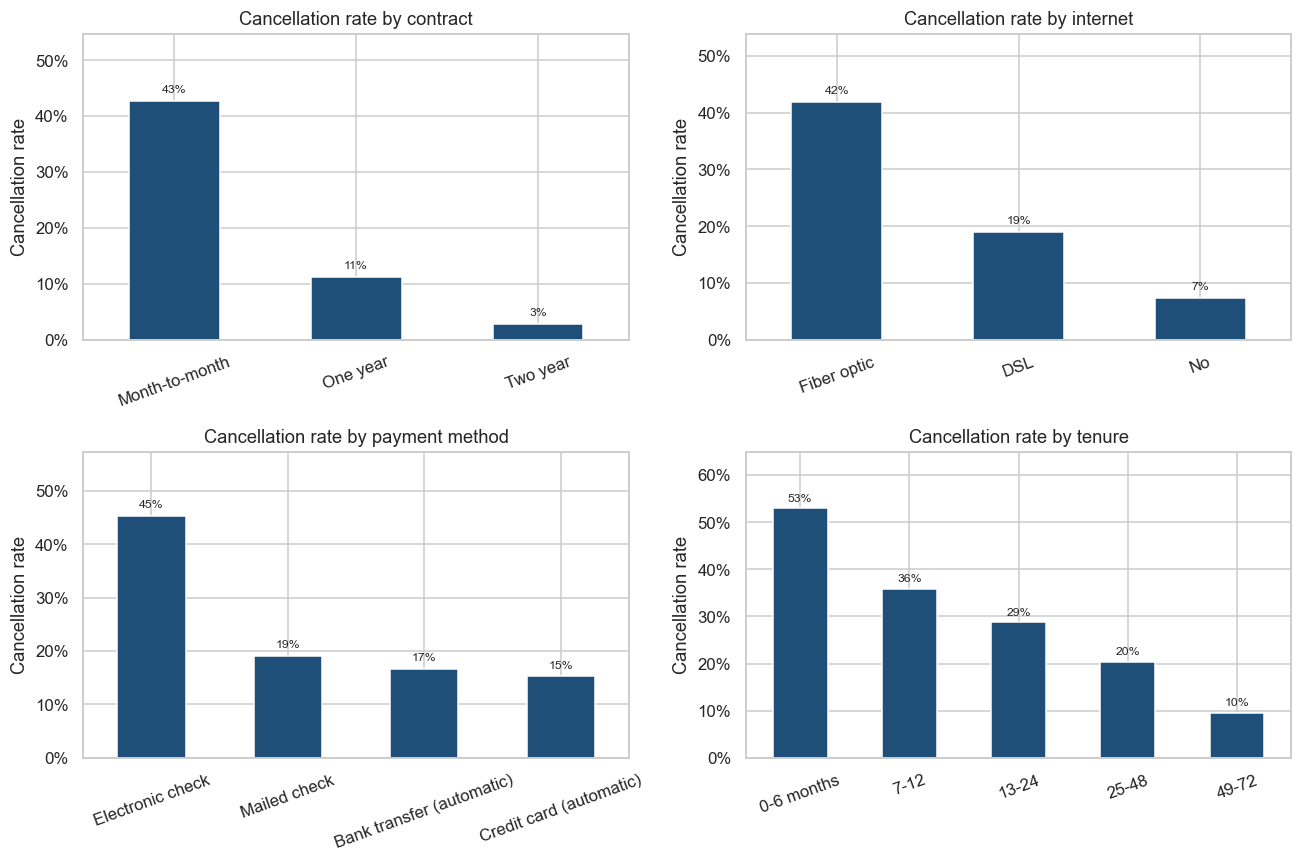

In [5]:
def rate_bars(ax, frame, column, title):
    rates = frame.groupby(column, observed=True)["ChurnFlag"].mean().sort_values(ascending=False)
    rates.plot(kind="bar", ax=ax, color="#1f4e79", rot=20)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Cancellation rate")
    ax.set_ylim(0, min(1.0, rates.max() + 0.12))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    for i, value in enumerate(rates.values):
        ax.text(i, value + 0.015, f"{value:.0%}", ha="center", fontsize=8)


fig, axes = plt.subplots(2, 2, figsize=(12, 8))
rate_bars(axes[0, 0], eda, "Contract", "Cancellation rate by contract")
rate_bars(axes[0, 1], eda, "InternetService", "Cancellation rate by internet")
rate_bars(axes[1, 0], eda, "PaymentMethod", "Cancellation rate by payment method")
rate_bars(axes[1, 1], eda, "TenureBand", "Cancellation rate by tenure")
fig.tight_layout()
plt.show()


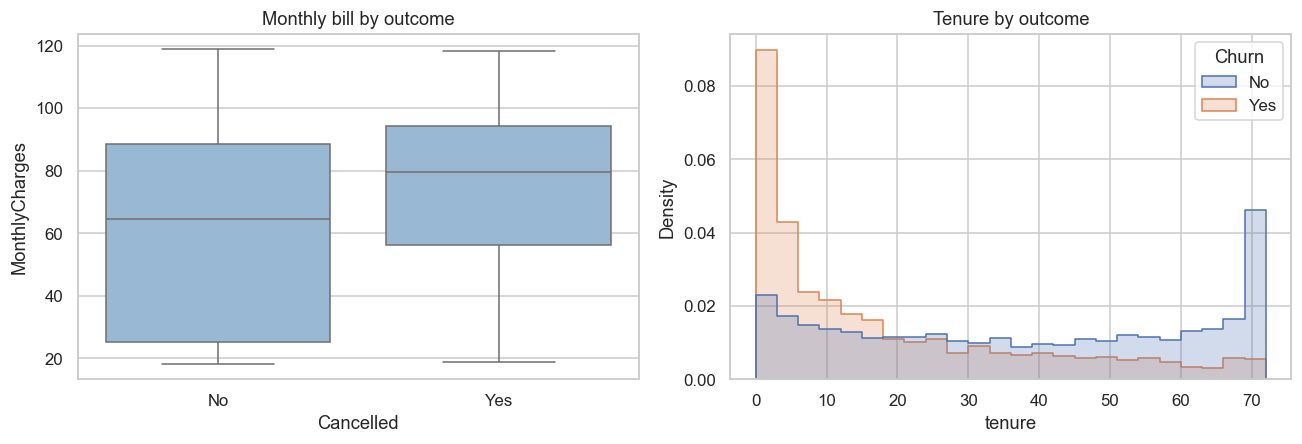

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.boxplot(data=eda, x="Churn", y="MonthlyCharges", ax=axes[0], color="#8fb8de")
axes[0].set_title("Monthly bill by outcome")
axes[0].set_xlabel("Cancelled")
sns.histplot(data=eda, x="tenure", hue="Churn", bins=24, element="step", stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("Tenure by outcome")
fig.tight_layout()
plt.show()


## Choose the model inputs

The model uses the service, contract, billing, and household fields. `customerID` is an identifier, so it stays out of the model. `Churn` is the target, stored as `ChurnFlag`.


In [7]:
TARGET = "ChurnFlag"
NUM_COLS = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
CAT_COLS = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
]
FEATURE_COLS = NUM_COLS + CAT_COLS

X = df[FEATURE_COLS].copy()
y = df[TARGET].copy()
print(f"Customers: {len(X):,}")
print(f"Numeric inputs: {NUM_COLS}")
print(f"Categorical inputs: {len(CAT_COLS)}")
print(f"Cancellation rate: {y.mean():.1%}")


Customers: 7,043
Numeric inputs: ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
Categorical inputs: 15
Cancellation rate: 26.5%


## Hold out validation and test customers

The split is 60% train, 20% validation, and 20% test. The validation slice chooses the model and the decision threshold. The test slice is scored once, after those choices are locked.


In [8]:
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=RANDOM_STATE
)

split_summary = pd.DataFrame(
    {
        "customers": [len(y_train), len(y_val), len(y_test)],
        "cancellation_rate": [y_train.mean(), y_val.mean(), y_test.mean()],
    },
    index=["Train", "Validation", "Test"],
)
split_summary["cancellation_rate"] = split_summary["cancellation_rate"].map(lambda v: f"{v:.1%}")
display(split_summary)


,customers,cancellation_rate
Train,4225,26.5%
Validation,1409,26.5%
Test,1409,26.5%


## Fit logistic regression, random forest, and XGBoost

All three models see the same training customers.

- Logistic regression is scaled, so bill size and tenure share a common unit. Class weights balance the two outcomes.
- Random forest and XGBoost keep the original units. They also up-weight cancellations, because only about one customer in four cancelled.
- Categories are one-hot encoded inside the pipeline, fit on the training rows only.


In [9]:
MODEL_NAMES = ["Logistic Regression", "Random Forest", "XGBoost"]


def make_preprocessor(scale_numeric):
    numeric = StandardScaler() if scale_numeric else "passthrough"
    return ColumnTransformer(
        transformers=[
            ("num", numeric, NUM_COLS),
            (
                "cat",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                CAT_COLS,
            ),
        ]
    )


def build_model(name, y_fit):
    positives = max(int((y_fit == 1).sum()), 1)
    negatives = int((y_fit == 0).sum())
    scale_pos_weight = negatives / positives
    if name == "Logistic Regression":
        estimator = LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )
        scale_numeric = True
    elif name == "Random Forest":
        estimator = RandomForestClassifier(
            n_estimators=200,
            max_depth=12,
            min_samples_leaf=8,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=1,
        )
        scale_numeric = False
    elif name == "XGBoost":
        estimator = XGBClassifier(
            n_estimators=200,
            max_depth=3,
            learning_rate=0.08,
            subsample=0.9,
            colsample_bytree=0.9,
            min_child_weight=5,
            reg_lambda=1.0,
            scale_pos_weight=scale_pos_weight,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=1,
            verbosity=0,
        )
        scale_numeric = False
    else:
        raise ValueError(name)
    return Pipeline(
        steps=[
            ("prep", make_preprocessor(scale_numeric)),
            ("model", estimator),
        ]
    )


fitted = {}
scores = {}
for name in MODEL_NAMES:
    model = build_model(name, y_train)
    model.fit(X_train, y_train)
    fitted[name] = model
    scores[name] = {
        "train": model.predict_proba(X_train)[:, 1],
        "validation": model.predict_proba(X_val)[:, 1],
        "test": model.predict_proba(X_test)[:, 1],
    }
    print(
        f"{name}: train ROC-AUC {roc_auc_score(y_train, scores[name]['train']):.3f} | "
        f"validation ROC-AUC {roc_auc_score(y_val, scores[name]['validation']):.3f}"
    )


Logistic Regression: train ROC-AUC 0.853 | validation ROC-AUC 0.836
Random Forest: train ROC-AUC 0.912 | validation ROC-AUC 0.837
XGBoost: train ROC-AUC 0.894 | validation ROC-AUC 0.837


## Compare the three models

Validation average precision chooses the champion. Average precision is the right ranking score here because cancellations are the minority. Test numbers are the ones to quote: that slice did not choose the model.

Two references sit in the same table. A constant score has no ranking power. The month-to-month rule flags every month-to-month customer and nobody else.


In [10]:
def metric_row(name, y_true_val, p_val, y_true_test, p_test):
    return {
        "Model": name,
        "Validation ROC-AUC": roc_auc_score(y_true_val, p_val),
        "Validation average precision": average_precision_score(y_true_val, p_val),
        "Test ROC-AUC": roc_auc_score(y_true_test, p_test),
        "Test average precision": average_precision_score(y_true_test, p_test),
        "Test Brier": brier_score_loss(y_true_test, p_test),
    }


rows = []
constant_val = np.full(len(y_val), float(y_train.mean()))
constant_test = np.full(len(y_test), float(y_train.mean()))
rows.append(metric_row("Constant rate", y_val, constant_val, y_test, constant_test))

rule_val = (X_val["Contract"] == "Month-to-month").astype(float)
rule_test = (X_test["Contract"] == "Month-to-month").astype(float)
rows.append(metric_row("Month-to-month rule", y_val, rule_val, y_test, rule_test))

for name in MODEL_NAMES:
    rows.append(
        metric_row(
            name,
            y_val,
            scores[name]["validation"],
            y_test,
            scores[name]["test"],
        )
    )

comparison = pd.DataFrame(rows).set_index("Model")
champion = (
    comparison.loc[MODEL_NAMES, "Validation average precision"].sort_values(ascending=False).index[0]
)
print(f"Champion by validation average precision: {champion}")
display(comparison.round(3))


Champion by validation average precision: XGBoost


,Validation ROC-AUC,Validation average precision,Test ROC-AUC,Test average precision,Test Brier
Model,,,,,
Constant rate,0.500,0.265,0.500,0.265,0.195
Month-to-month rule,0.715,0.397,0.725,0.406,0.347
Logistic Regression,0.836,0.643,0.843,0.633,0.168
Random Forest,0.837,0.632,0.840,0.640,0.157
XGBoost,0.837,0.647,0.845,0.658,0.161


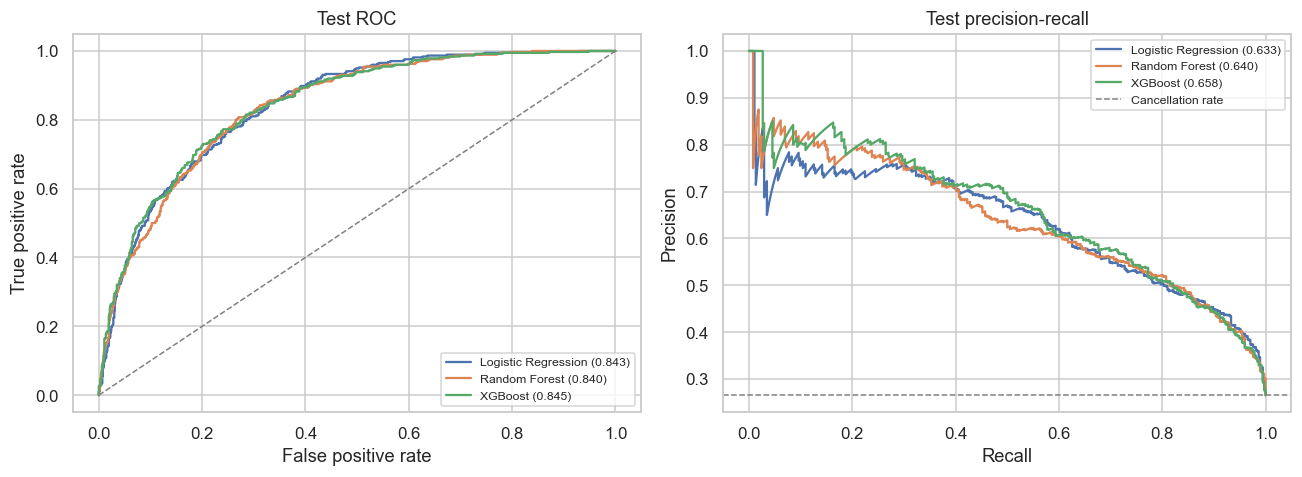

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name in MODEL_NAMES:
    fpr, tpr, _ = roc_curve(y_test, scores[name]["test"])
    precision, recall, _ = precision_recall_curve(y_test, scores[name]["test"])
    test_auc = roc_auc_score(y_test, scores[name]["test"])
    test_ap = average_precision_score(y_test, scores[name]["test"])
    axes[0].plot(fpr, tpr, label=f"{name} ({test_auc:.3f})")
    axes[1].plot(recall, precision, label=f"{name} ({test_ap:.3f})")

axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)
axes[0].set_title("Test ROC")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].legend(loc="lower right", fontsize=8)
axes[1].axhline(y_test.mean(), linestyle="--", color="gray", linewidth=1, label="Cancellation rate")
axes[1].set_title("Test precision-recall")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()


## Choose a yes/no decision threshold

The champion's raw score is turned into a calibrated probability in the next step. This cell waits until those probabilities exist. The threshold itself is the validation cutoff with the best F1, then frozen and applied to the test customers.


In [12]:
def best_f1_threshold(y_true, probabilities):
    grid = np.round(np.linspace(0.10, 0.80, 71), 4)
    f1_scores = [f1_score(y_true, probabilities >= t, zero_division=0) for t in grid]
    best_at = int(np.argmax(f1_scores))
    return float(grid[best_at]), float(f1_scores[best_at])


## Calibrate the cancellation probability

Class weights push the raw scores upward, so a raw 0.70 is not yet "70% of similar customers cancel." Platt scaling is fit on the validation scores, then applied to the test scores. The reliability chart compares the raw and calibrated scores on the test customers.


In [13]:
p_val_raw = scores[champion]["validation"]
p_test_raw = scores[champion]["test"]

platt = LogisticRegression(max_iter=1000)
platt.fit(p_val_raw.reshape(-1, 1), y_val)
p_val = platt.predict_proba(p_val_raw.reshape(-1, 1))[:, 1]
p_test = platt.predict_proba(p_test_raw.reshape(-1, 1))[:, 1]

threshold, validation_f1 = best_f1_threshold(y_val, p_val)
test_predictions = (p_test >= threshold).astype(int)

print(f"Champion: {champion}")
print(f"Decision threshold (chosen on validation): {threshold:.2f}")
print(f"Validation F1 at that threshold: {validation_f1:.3f}")
print(f"Test F1: {f1_score(y_test, test_predictions):.3f}")
print(f"Test precision: {precision_score(y_test, test_predictions):.3f}")
print(f"Test recall: {recall_score(y_test, test_predictions):.3f}")
print(f"Test Brier, raw scores: {brier_score_loss(y_test, p_test_raw):.3f}")
print(f"Test Brier, calibrated: {brier_score_loss(y_test, p_test):.3f}")
print()
print(classification_report(y_test, test_predictions, target_names=["Stay", "Cancel"], digits=3))

confusion = pd.DataFrame(
    confusion_matrix(y_test, test_predictions),
    index=["Actual stay", "Actual cancel"],
    columns=["Predicted stay", "Predicted cancel"],
)
display(confusion)


Champion: XGBoost
Decision threshold (chosen on validation): 0.37
Validation F1 at that threshold: 0.637
Test F1: 0.636
Test precision: 0.574
Test recall: 0.714
Test Brier, raw scores: 0.161
Test Brier, calibrated: 0.136

              precision    recall  f1-score   support

        Stay      0.887     0.809     0.846      1035
      Cancel      0.574     0.714     0.636       374

    accuracy                          0.784      1409
   macro avg      0.730     0.761     0.741      1409
weighted avg      0.804     0.784     0.790      1409



,Predicted stay,Predicted cancel
Actual stay,837,198
Actual cancel,107,267


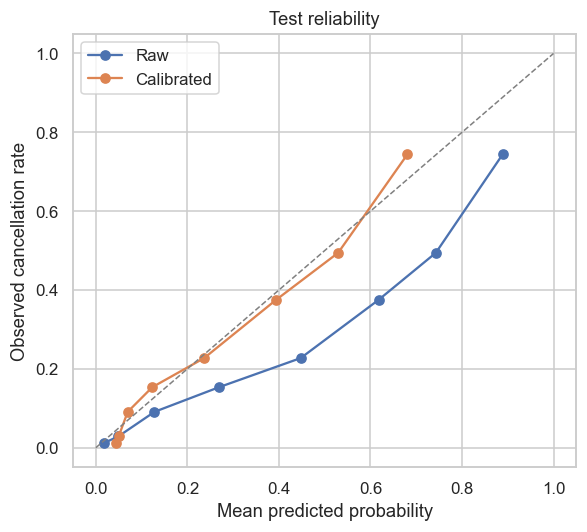

In [14]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for label, probabilities in [("Raw", p_test_raw), ("Calibrated", p_test)]:
    fraction, mean_predicted = calibration_curve(y_test, probabilities, n_bins=8, strategy="quantile")
    ax.plot(mean_predicted, fraction, marker="o", label=label)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed cancellation rate")
ax.set_title("Test reliability")
ax.legend()
fig.tight_layout()
plt.show()


In [15]:
test_view = pd.DataFrame({"cancelled": y_test.to_numpy(), "probability": p_test})
test_view["decile"] = pd.qcut(test_view["probability"], 10, labels=False, duplicates="drop") + 1
deciles = (
    test_view.groupby("decile")
    .agg(customers=("cancelled", "size"), cancellation_rate=("cancelled", "mean"), mean_probability=("probability", "mean"))
    .sort_index()
)
deciles["cancellation_rate"] = deciles["cancellation_rate"].map(lambda v: f"{v:.1%}")
deciles["mean_probability"] = deciles["mean_probability"].map(lambda v: f"{v:.1%}")
print("Test customers grouped by calibrated probability. Decile 10 is the highest risk.")
display(deciles)


Test customers grouped by calibrated probability. Decile 10 is the highest risk.


,customers,cancellation_rate,mean_probability
decile,,,
1,141,1.4%,4.3%
2,141,0.7%,4.7%
3,141,6.4%,5.6%
4,141,10.6%,8.0%
5,141,16.3%,13.0%
6,140,23.6%,21.9%
7,141,29.1%,34.8%
8,141,40.4%,46.3%
9,141,58.9%,57.2%


## Explain the model with SHAP

SHAP assigns each input a share of the model's score for that customer. A positive value pushes the customer toward cancellation. The beeswarm shows the pattern across the test customers. The waterfall charts show three high-scoring test customers one at a time.

Logistic regression also has a direct reading: the sign of each coefficient. That chart is included so the linear model stays readable when another model wins the comparison. SHAP explains the champion.


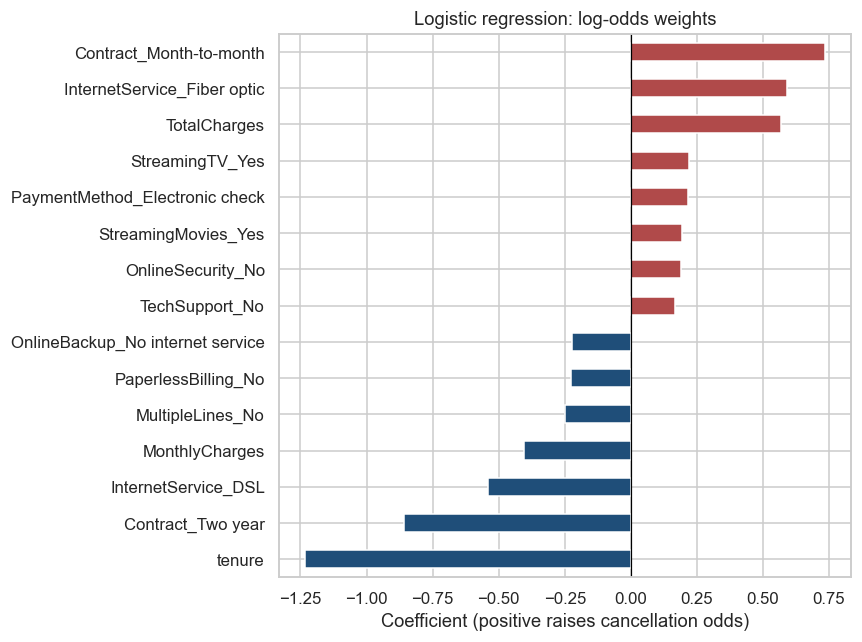

In [16]:
def transformed_frame(pipeline, frame):
    preprocessor = pipeline.named_steps["prep"]
    matrix = np.asarray(preprocessor.transform(frame))
    names = [name.split("__", 1)[-1] for name in preprocessor.get_feature_names_out()]
    return pd.DataFrame(matrix, columns=names, index=frame.index)


def positive_explanation(explanation):
    values = np.asarray(explanation.values)
    if values.ndim == 2:
        return explanation
    return explanation[..., 1]


def make_tree_explainer(model):
    try:
        return shap.TreeExplainer(model)
    except Exception:
        booster = model.get_booster()
        config = json.loads(booster.save_config())
        base_score = config["learner"]["learner_model_param"]["base_score"]
        if isinstance(base_score, str) and base_score.startswith("["):
            config["learner"]["learner_model_param"]["base_score"] = str(float(base_score.strip("[]")))
            booster.load_config(json.dumps(config))
        return shap.TreeExplainer(booster)


def explain_rows(pipeline, frame):
    model = pipeline.named_steps["model"]
    data = transformed_frame(pipeline, frame)
    if isinstance(model, LogisticRegression):
        background = data.sample(n=min(200, len(data)), random_state=RANDOM_STATE)
        explainer = shap.LinearExplainer(model, background)
    else:
        explainer = make_tree_explainer(model)
    return positive_explanation(explainer(data))


lr_pipe = fitted["Logistic Regression"]
lr_names = transformed_frame(lr_pipe, X_train.head(2)).columns
lr_coefs = pd.Series(lr_pipe.named_steps["model"].coef_[0], index=lr_names)
lr_top = pd.concat([lr_coefs.nsmallest(8), lr_coefs.nlargest(8)]).drop_duplicates().sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
colors = ["#b04a4a" if value > 0 else "#1f4e79" for value in lr_top.values]
lr_top.plot(kind="barh", ax=ax, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Logistic regression: log-odds weights")
ax.set_xlabel("Coefficient (positive raises cancellation odds)")
fig.tight_layout()
plt.show()


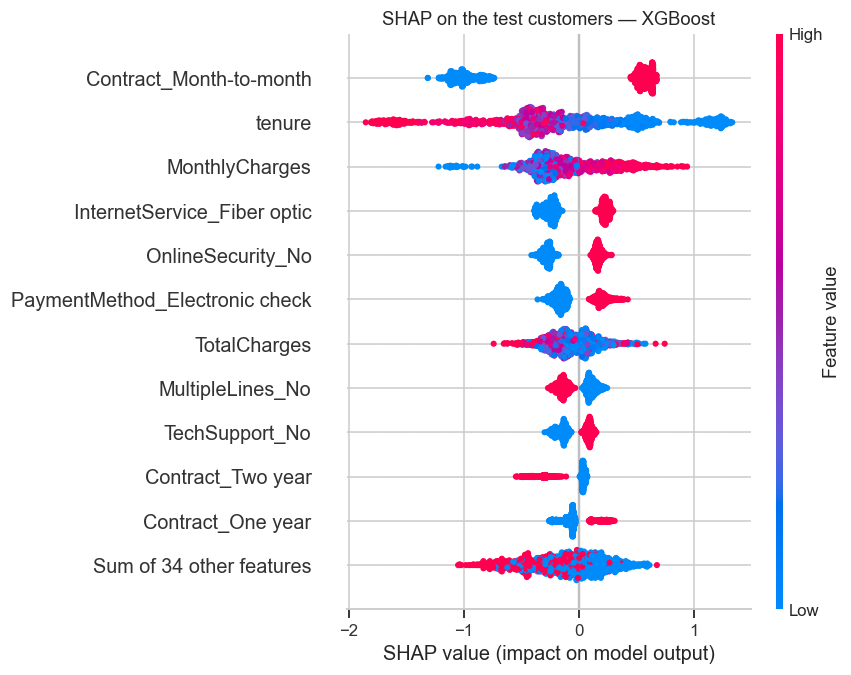

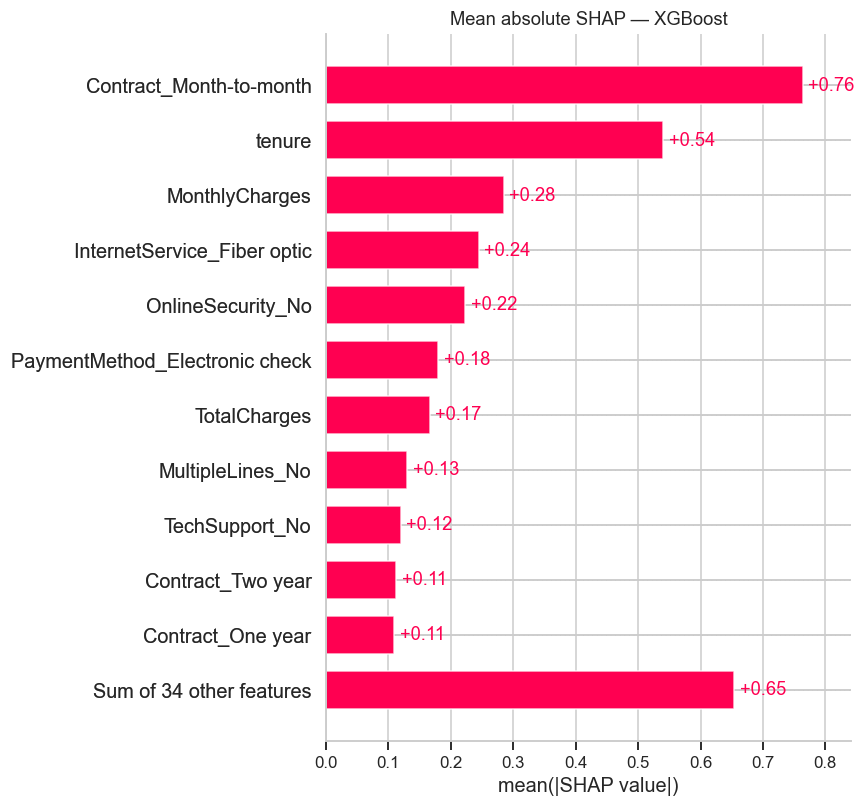

In [17]:
champion_pipe = fitted[champion]
test_explanation = explain_rows(champion_pipe, X_test)

shap.plots.beeswarm(test_explanation, max_display=12, show=False)
plt.title(f"SHAP on the test customers — {champion}")
plt.tight_layout()
plt.show()

shap.plots.bar(test_explanation, max_display=12, show=False)
plt.title(f"Mean absolute SHAP — {champion}")
plt.tight_layout()
plt.show()


Example 1: 5178-LMXOP | calibrated probability 76.2% | this customer cancelled


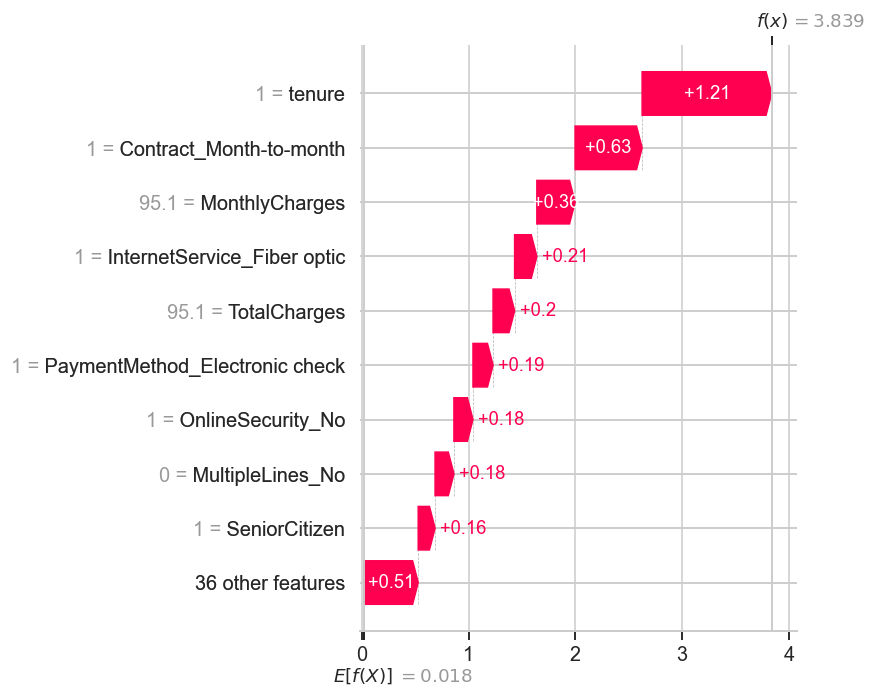

Example 2: 0295-PPHDO | calibrated probability 75.9% | this customer cancelled


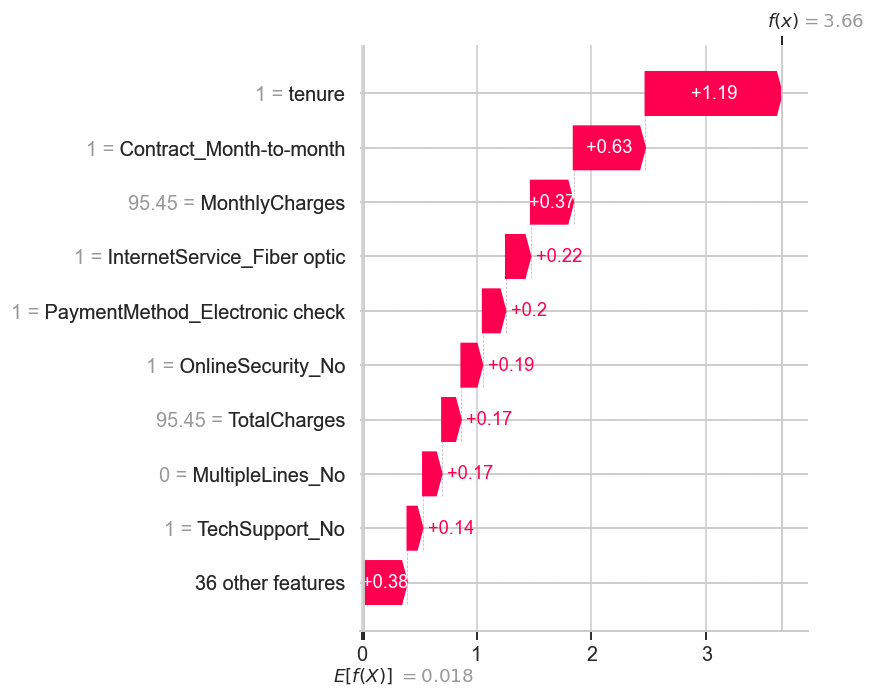

Example 3: 1069-XAIEM | calibrated probability 75.8% | this customer cancelled


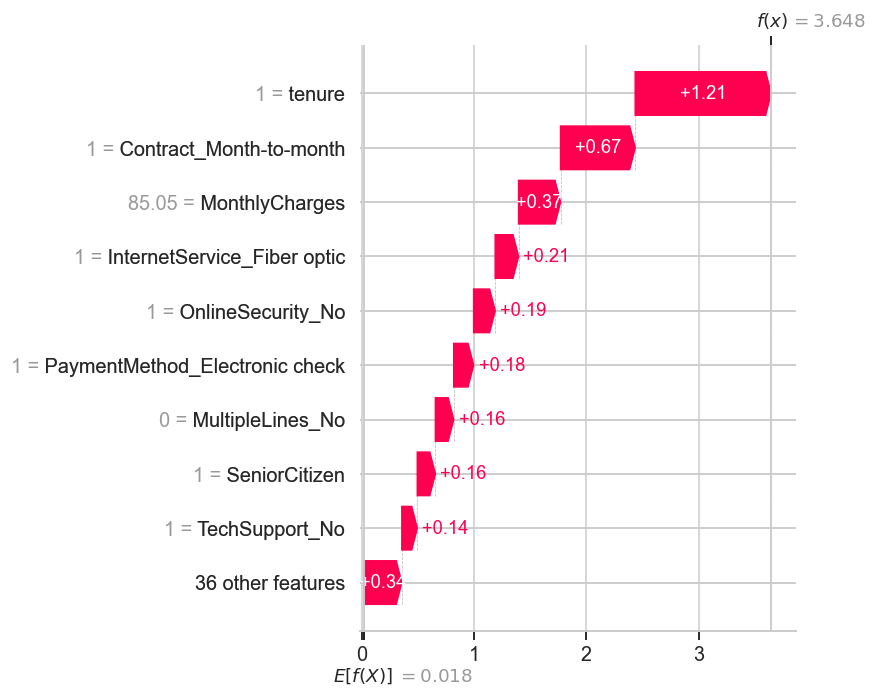

In [18]:
demo_positions = np.argsort(-p_test)[:3]
for rank, position in enumerate(demo_positions, start=1):
    row_index = X_test.index[position]
    customer_id = df.loc[row_index, "customerID"]
    outcome = "cancelled" if int(y_test.loc[row_index]) == 1 else "stayed"
    probability = p_test[position]
    print(
        f"Example {rank}: {customer_id} | calibrated probability {probability:.1%} | "
        f"this customer {outcome}"
    )
    shap.plots.waterfall(test_explanation[position], max_display=10, show=False)
    plt.tight_layout()
    plt.show()


## Score every customer without training on that customer

The test metrics above use one frozen model. The call list needs a score for every subscriber, including people who were in the training slice.

Five-fold cross-validation scores each customer with a champion model that did not train on that customer. Inside each fold, Platt scaling is fit on a calibration slice of the training fold so the call-list probabilities sit on the same kind of scale as the calibrated probabilities above.


In [19]:
oof_probability = np.zeros(len(y), dtype=float)
folder = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for fold, (train_pos, test_pos) in enumerate(folder.split(X, y), start=1):
    inner_pos, cal_pos = train_test_split(
        train_pos,
        test_size=0.25,
        stratify=y.iloc[train_pos],
        random_state=RANDOM_STATE,
    )
    fold_model = build_model(champion, y.iloc[inner_pos])
    fold_model.fit(X.iloc[inner_pos], y.iloc[inner_pos])
    fold_platt = LogisticRegression(max_iter=1000)
    p_cal = fold_model.predict_proba(X.iloc[cal_pos])[:, 1]
    fold_platt.fit(p_cal.reshape(-1, 1), y.iloc[cal_pos])
    p_holdout = fold_model.predict_proba(X.iloc[test_pos])[:, 1]
    oof_probability[test_pos] = fold_platt.predict_proba(p_holdout.reshape(-1, 1))[:, 1]
    print(f"Fold {fold}: scored {len(test_pos):,} customers")

print(f"Actual cancellation rate: {y.mean():.1%}")
print(f"Mean cross-validated probability: {oof_probability.mean():.1%}")
print(f"Cross-validated ROC-AUC: {roc_auc_score(y, oof_probability):.3f}")
print(f"Cross-validated average precision: {average_precision_score(y, oof_probability):.3f}")


Fold 1: scored 1,409 customers
Fold 2: scored 1,409 customers
Fold 3: scored 1,409 customers
Fold 4: scored 1,408 customers
Fold 5: scored 1,408 customers
Actual cancellation rate: 26.5%
Mean cross-validated probability: 26.4%
Cross-validated ROC-AUC: 0.844
Cross-validated average precision: 0.661


## Price a retention offer for each current subscriber

The queue is current subscribers only. Someone who already cancelled needs a win-back offer, which is a different program.

For each active customer the notebook prices six offers and keeps the one with the highest expected net margin.

Assumptions, edited in the block below:

- Gross margin on the subscription is 40%.
- A saved customer stays 6 more months.
- Contacting a customer costs $8.
- `effectiveness` is the share of would-be cancellations that the offer prevents.
- `uptake` is the share of contacted customers who redeem the incentive, including people who would have stayed.

Expected recovered margin = probability × effectiveness × monthly bill × 6 × 40%.

Expected cost = $8 + uptake × face value of the incentive.

Expected net value = recovered margin − cost.

A customer is worth contacting when expected net value is above zero. The rank is that dollar value, highest first.

| Tier | Rule |
| --- | --- |
| P1 — call this week | expected net value of at least $15 |
| P2 — offer this month | expected net value of at least $6 |
| P3 — low-cost nurture | expected net value above $0 |
| Hold | expected net value of $0 or below |


In [20]:
HORIZON_MONTHS = 6
MARGIN = 0.40
CONTACT_COST = 8.0

OFFERS = [
    {
        "name": "Early-life credit",
        "effectiveness": 0.25,
        "uptake": 0.40,
        "why": "A one-time credit for a month-to-month customer in the first six months, before the service becomes a habit.",
        "eligible": lambda row: row["Contract"] == "Month-to-month" and row["tenure"] <= 6,
        "face": lambda row: float(min(40.0, 0.5 * row["MonthlyCharges"])),
    },
    {
        "name": "Annual contract save",
        "effectiveness": 0.30,
        "uptake": 0.45,
        "why": "10% off for six months in exchange for moving a month-to-month customer onto a 12-month commitment.",
        "eligible": lambda row: row["Contract"] == "Month-to-month" and row["tenure"] > 6,
        "face": lambda row: float(0.10 * row["MonthlyCharges"] * HORIZON_MONTHS),
    },
    {
        "name": "Tech support bundle",
        "effectiveness": 0.20,
        "uptake": 0.35,
        "why": "Three months of tech support for an internet customer who does not have it.",
        "eligible": lambda row: row["InternetService"] != "No" and row["TechSupport"] == "No",
        "face": lambda row: 30.0,
    },
    {
        "name": "Online security bundle",
        "effectiveness": 0.15,
        "uptake": 0.30,
        "why": "Two months of online security for an internet customer who does not have it.",
        "eligible": lambda row: row["InternetService"] != "No" and row["OnlineSecurity"] == "No",
        "face": lambda row: 20.0,
    },
    {
        "name": "Autopay incentive",
        "effectiveness": 0.12,
        "uptake": 0.40,
        "why": "A $10 credit to move an electronic-check customer onto autopay.",
        "eligible": lambda row: row["PaymentMethod"] == "Electronic check",
        "face": lambda row: 10.0,
    },
    {
        "name": "Courtesy save call",
        "effectiveness": 0.08,
        "uptake": 0.0,
        "why": "A short call with no discount, used when a paid incentive would cost more than the margin it can save.",
        "eligible": lambda row: True,
        "face": lambda row: 0.0,
    },
]


def assign_tier(net_value):
    if net_value >= 15:
        return "P1 — call this week"
    if net_value >= 6:
        return "P2 — offer this month"
    if net_value > 0:
        return "P3 — low-cost nurture"
    return "Hold"


def best_offer(row):
    probability = float(row["churn_probability"])
    monthly = float(row["MonthlyCharges"])
    best = None
    for offer in OFFERS:
        if not offer["eligible"](row):
            continue
        face = float(offer["face"](row))
        effectiveness = float(offer["effectiveness"])
        uptake = float(offer["uptake"])
        recovered = probability * effectiveness * monthly * HORIZON_MONTHS * MARGIN
        expected_cost = CONTACT_COST + uptake * face
        net_value = recovered - expected_cost
        record = {
            "recommended_offer": offer["name"],
            "offer_rationale": offer["why"],
            "incentive_face_value": round(face, 2),
            "expected_recovered_margin": round(recovered, 2),
            "expected_offer_cost": round(expected_cost, 2),
            "expected_net_value": round(net_value, 2),
            "value_at_risk": round(probability * monthly * HORIZON_MONTHS * MARGIN, 2),
        }
        if best is None or record["expected_net_value"] > best["expected_net_value"]:
            best = record
    return pd.Series(best)


scored = df.copy()
scored["churn_probability"] = oof_probability
active = scored.loc[scored["ChurnFlag"] == 0].copy()
queue = pd.concat([active, active.apply(best_offer, axis=1)], axis=1)
queue = queue.sort_values(["expected_net_value", "churn_probability"], ascending=False)
queue["priority_rank"] = np.arange(1, len(queue) + 1)
queue["priority_tier"] = queue["expected_net_value"].map(assign_tier)
queue["top_risk_drivers"] = ""

tier_summary = (
    queue.groupby("priority_tier", sort=False)
    .agg(
        customers=("customerID", "size"),
        expected_net_value=("expected_net_value", "sum"),
        mean_probability=("churn_probability", "mean"),
        monthly_revenue=("MonthlyCharges", "sum"),
    )
    .reindex(["P1 — call this week", "P2 — offer this month", "P3 — low-cost nurture", "Hold"])
)
print(f"Current subscribers: {len(queue):,}")
display(tier_summary.round(2))


Current subscribers: 5,174


,customers,expected_net_value,mean_probability,monthly_revenue
priority_tier,,,,
P1 — call this week,17,283.98,0.70,1695.25
P2 — offer this month,213,2003.53,0.63,19314.75
P3 — low-cost nurture,335,978.87,0.52,28744.30
Hold,4609,-28976.85,0.14,267231.45


## Attach the reasons and rank the call list

The drivers come from the champion trained on the training customers, applied to the customers the offer math put at the top of the list. The number in brackets is the SHAP contribution in the model's score units. Positive means that field pushed this customer toward cancellation.

The cumulative chart is the work plan: start at rank 1 and stop when the extra calls no longer add net margin.


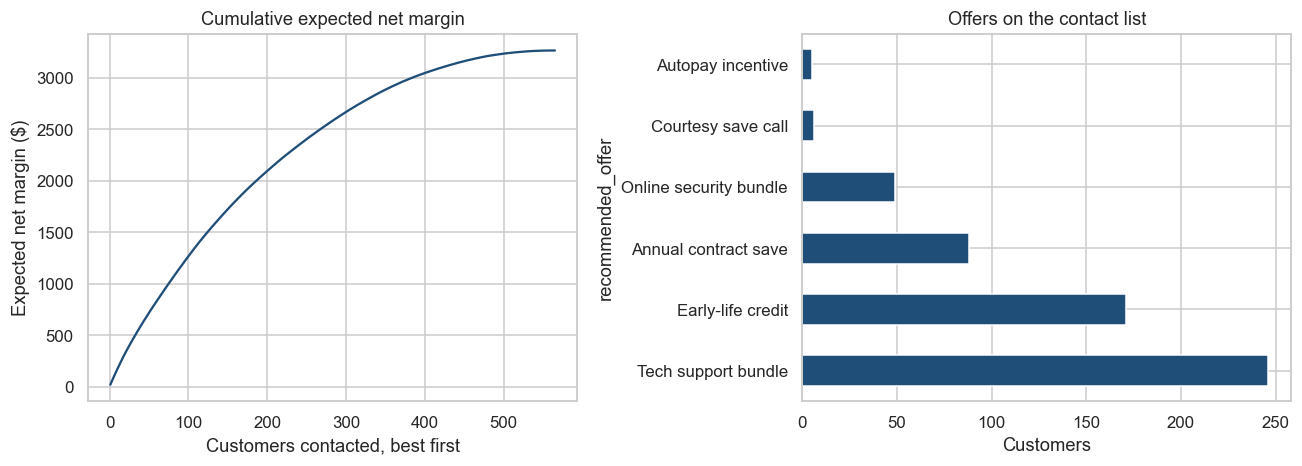

First 15 calls


,priority_rank,priority_tier,customerID,churn_probability,expected_net_value,recommended_offer,MonthlyCharges,tenure,Contract,InternetService,PaymentMethod,top_risk_drivers
678,1,P1 — call this week,5760-IFJOZ,0.670,19.38,Early-life credit,107.95,3,Month-to-month,Fiber optic,Mailed check,tenure is 3 [+0.60]; Contract is Month-to-month [+0.57]; MonthlyCharges is 108.0 [+0.36]
1719,2,P1 — call this week,2081-VEYEH,0.652,18.22,Early-life credit,107.95,3,Month-to-month,Fiber optic,Electronic check,tenure is 3 [+0.60]; Contract is Month-to-month [+0.54]; MonthlyCharges is 108.0 [+0.41]
2238,3,P1 — call this week,1393-IMKZG,0.719,17.36,Early-life credit,95.85,1,Month-to-month,Fiber optic,Electronic check,tenure is 1 [+0.89]; Contract is Month-to-month [+0.57]; MonthlyCharges is 95.8 [+0.33]
2582,4,P1 — call this week,7145-FEJWU,0.708,17.31,Tech support bundle,105.30,12,Month-to-month,Fiber optic,Electronic check,Contract is Month-to-month [+0.53]; MonthlyCharges is 105.3 [+0.28]; InternetService is Fiber optic [+0.26]
2387,5,P1 — call this week,6734-GMPVK,0.652,17.19,Early-life credit,105.30,5,Month-to-month,Fiber optic,Electronic check,Contract is Month-to-month [+0.56]; tenure is 5 [+0.53]; MonthlyCharges is 105.3 [+0.30]
4039,6,P1 — call this week,8161-QYMTT,0.746,17.10,Annual contract save,94.10,7,Month-to-month,Fiber optic,Electronic check,Contract is Month-to-month [+0.62]; tenure is 7 [+0.44]; MonthlyCharges is 94.1 [+0.35]
1724,7,P1 — call this week,7398-SKNQZ,0.718,16.87,Early-life credit,94.90,3,Month-to-month,Fiber optic,Electronic check,tenure is 3 [+0.61]; Contract is Month-to-month [+0.59]; MonthlyCharges is 94.9 [+0.33]
3270,8,P1 — call this week,4132-KALRO,0.674,16.76,Early-life credit,100.85,4,Month-to-month,Fiber optic,Mailed check,tenure is 4 [+0.79]; Contract is Month-to-month [+0.57]; MonthlyCharges is 100.8 [+0.48]
2519,9,P1 — call this week,4927-WWOOZ,0.735,16.31,Early-life credit,91.45,2,Month-to-month,Fiber optic,Electronic check,Contract is Month-to-month [+0.65]; tenure is 2 [+0.64]; PaymentMethod is Electronic check [+0.23]
5307,10,P1 — call this week,1941-HOSAM,0.744,16.25,Early-life credit,90.10,1,Month-to-month,Fiber optic,Electronic check,tenure is 1 [+1.22]; Contract is Month-to-month [+0.66]; InternetService is Fiber optic [+0.22]


In [21]:
def pretty_driver(name, value):
    for column in CAT_COLS:
        prefix = column + "_"
        if name.startswith(prefix):
            level = name[len(prefix):]
            if float(value) >= 0.5:
                return f"{column} is {level}"
            return f"{column} is not {level}"
    number = float(value)
    if abs(number - round(number)) < 1e-6:
        return f"{name} is {int(round(number))}"
    return f"{name} is {number:.1f}"


def top_drivers(shap_row, data_row, names, k=3):
    order = np.argsort(-np.asarray(shap_row))
    parts = []
    for position in order:
        if shap_row[position] <= 0 or len(parts) >= k:
            break
        parts.append(f"{pretty_driver(names[position], data_row[position])} [{shap_row[position]:+.2f}]")
    return "; ".join(parts)


contact_index = queue.loc[queue["expected_net_value"] > 0].head(300).index
focus_explanation = explain_rows(champion_pipe, X.loc[contact_index])
shap_values = np.asarray(focus_explanation.values)
shap_data = np.asarray(focus_explanation.data)
shap_names = list(focus_explanation.feature_names)
driver_text = [
    top_drivers(shap_values[i], shap_data[i], shap_names)
    for i in range(len(contact_index))
]
queue.loc[contact_index, "top_risk_drivers"] = driver_text

contact = queue.loc[queue["expected_net_value"] > 0].copy()
contact["cumulative_net"] = contact["expected_net_value"].cumsum()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].plot(contact["priority_rank"], contact["cumulative_net"], color="#1f4e79")
axes[0].set_title("Cumulative expected net margin")
axes[0].set_xlabel("Customers contacted, best first")
axes[0].set_ylabel("Expected net margin ($)")
offer_counts = contact["recommended_offer"].value_counts()
offer_counts.plot(kind="barh", ax=axes[1], color="#1f4e79")
axes[1].set_title("Offers on the contact list")
axes[1].set_xlabel("Customers")
fig.tight_layout()
plt.show()

preview_cols = [
    "priority_rank",
    "priority_tier",
    "customerID",
    "churn_probability",
    "expected_net_value",
    "recommended_offer",
    "MonthlyCharges",
    "tenure",
    "Contract",
    "InternetService",
    "PaymentMethod",
    "top_risk_drivers",
]
print("First 15 calls")
display(contact[preview_cols].head(15).round(3))


## Save the list and read the briefing

`retention_priority_list.csv` holds every current subscriber, best call first. Work down `priority_rank` and stop at the first `Hold` row. The effectiveness and margin figures are planning assumptions until a live campaign measures them.


In [22]:
export_cols = [
    "priority_rank",
    "priority_tier",
    "customerID",
    "churn_probability",
    "expected_net_value",
    "value_at_risk",
    "expected_recovered_margin",
    "expected_offer_cost",
    "recommended_offer",
    "incentive_face_value",
    "offer_rationale",
    "top_risk_drivers",
    "tenure",
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity",
    "MonthlyCharges",
    "PaperlessBilling",
    "Partner",
    "Dependents",
    "SeniorCitizen",
]
export = queue[export_cols].copy()
export["churn_probability"] = export["churn_probability"].round(4)
export_path = "retention_priority_list.csv"
export.to_csv(export_path, index=False)

top_200_net = float(contact.head(200)["expected_net_value"].sum()) if len(contact) else 0.0
champion_test_auc = float(roc_auc_score(y_test, p_test_raw))
champion_test_ap = float(average_precision_score(y_test, p_test_raw))
test_precision = float(precision_score(y_test, test_predictions, zero_division=0))
test_recall = float(recall_score(y_test, test_predictions, zero_division=0))
highest_decile = test_view.loc[test_view["decile"] == test_view["decile"].max(), "cancelled"].mean()

briefing = f"""
### Briefing

- Champion model: **{champion}**. Test ROC-AUC **{champion_test_auc:.3f}**. Test average precision **{champion_test_ap:.3f}**.
- At probability **{threshold:.2f}**, test precision is **{test_precision:.1%}** and test recall is **{test_recall:.1%}**.
- In the highest test decile, **{highest_decile:.1%}** of customers cancelled. The base rate is **{y_test.mean():.1%}**.
- Current subscribers on the list: **{len(queue):,}**. Worth contacting (expected net value above zero): **{len(contact):,}**.
- Expected net margin if the whole contact list is worked: **${contact['expected_net_value'].sum():,.0f}**.
- Expected net margin in the first 200 calls: **${top_200_net:,.0f}**.
- Saved file: `{export_path}`.
"""
display(Markdown(briefing))
print(f"Wrote {len(export):,} rows to {export_path}")



### Briefing

- Champion model: **XGBoost**. Test ROC-AUC **0.845**. Test average precision **0.658**.
- At probability **0.37**, test precision is **57.4%** and test recall is **71.4%**.
- In the highest test decile, **78.0%** of customers cancelled. The base rate is **26.5%**.
- Current subscribers on the list: **5,174**. Worth contacting (expected net value above zero): **565**.
- Expected net margin if the whole contact list is worked: **$3,266**.
- Expected net margin in the first 200 calls: **$2,096**.
- Saved file: `retention_priority_list.csv`.


Wrote 5,174 rows to retention_priority_list.csv


## Stress-test the offer assumptions

The call list uses a 40% margin, a six-month stay after a save, and a fixed success rate for each offer. Those figures are planning inputs. This section reprices every current subscriber when the margin, the offer success rate, or the share of customers who redeem a discount moves, and checks whether the same people stay at the top.

`Effectiveness scale` multiplies every offer's save rate. `Uptake scale` multiplies the share who redeem the incentive. A scale of 1.0 is the base list.


In [23]:

def offer_masks_and_faces(frame):
    monthly = frame["MonthlyCharges"].to_numpy(dtype=float)
    month_to_month = frame["Contract"].eq("Month-to-month").to_numpy()
    has_internet = frame["InternetService"].ne("No").to_numpy()
    masks = {
        "Early-life credit": month_to_month & frame["tenure"].le(6).to_numpy(),
        "Annual contract save": month_to_month & frame["tenure"].gt(6).to_numpy(),
        "Tech support bundle": has_internet & frame["TechSupport"].eq("No").to_numpy(),
        "Online security bundle": has_internet & frame["OnlineSecurity"].eq("No").to_numpy(),
        "Autopay incentive": frame["PaymentMethod"].eq("Electronic check").to_numpy(),
        "Courtesy save call": np.ones(len(frame), dtype=bool),
    }
    faces = {
        "Early-life credit": np.minimum(40.0, 0.5 * monthly),
        "Annual contract save": 0.10 * monthly * HORIZON_MONTHS,
        "Tech support bundle": np.full(len(frame), 30.0),
        "Online security bundle": np.full(len(frame), 20.0),
        "Autopay incentive": np.full(len(frame), 10.0),
        "Courtesy save call": np.zeros(len(frame)),
    }
    return masks, faces


def price_book(frame, margin, effectiveness_scale, uptake_scale):
    probability = frame["churn_probability"].to_numpy(dtype=float)
    monthly = frame["MonthlyCharges"].to_numpy(dtype=float)
    masks, faces = offer_masks_and_faces(frame)
    best_net = np.full(len(frame), -1e18)
    best_name = np.empty(len(frame), dtype=object)
    for offer in OFFERS:
        name = offer["name"]
        eligible = masks[name]
        effectiveness = float(offer["effectiveness"]) * effectiveness_scale
        uptake = min(1.0, float(offer["uptake"]) * uptake_scale)
        recovered = probability * effectiveness * monthly * HORIZON_MONTHS * margin
        net_value = recovered - (CONTACT_COST + uptake * faces[name])
        better = eligible & (net_value > best_net)
        best_net[better] = net_value[better]
        best_name[better] = name
    return best_net, best_name


ranked = queue.sort_values("priority_rank")
base_top50 = set(ranked.head(50)["customerID"])


def scenario_row(label, margin, effectiveness_scale, uptake_scale):
    nets, _ = price_book(ranked, margin, effectiveness_scale, uptake_scale)
    order = np.argsort(-nets)
    top50 = set(ranked.iloc[order[:50]]["customerID"])
    worth = nets > 0
    return {
        "Case": label,
        "Margin": margin,
        "Effectiveness scale": effectiveness_scale,
        "Uptake scale": uptake_scale,
        "Worth contacting": int(worth.sum()),
        "Expected net ($)": round(float(nets[worth].sum()), 0) if worth.any() else 0,
        "Base top 50 retained": f"{len(base_top50 & top50) / len(base_top50):.0%}",
    }


scenario_table = pd.DataFrame(
    [
        scenario_row("Base", 0.40, 1.0, 1.0),
        scenario_row("Low margin", 0.25, 1.0, 1.0),
        scenario_row("High margin", 0.55, 1.0, 1.0),
        scenario_row("Offers save fewer people", 0.40, 0.5, 1.0),
        scenario_row("Offers save more people", 0.40, 1.5, 1.0),
        scenario_row("More customers redeem", 0.40, 1.0, 1.5),
        scenario_row("Fewer customers redeem", 0.40, 1.0, 0.5),
        scenario_row("Pessimistic", 0.30, 0.7, 1.3),
        scenario_row("Optimistic", 0.50, 1.3, 0.8),
    ]
)
base_net = float(queue.loc[queue["expected_net_value"] > 0, "expected_net_value"].sum())
print(f"Base list expected net: ${base_net:,.0f}")
display(scenario_table)


Base list expected net: $3,266


,Case,Margin,Effectiveness scale,Uptake scale,Worth contacting,Expected net ($),Base top 50 retained
0,Base,0.40,1.0,1.0,565,3266.0,100%
1,Low margin,0.25,1.0,1.0,61,65.0,88%
2,High margin,0.55,1.0,1.0,985,11058.0,82%
3,Offers save fewer people,0.40,0.5,1.0,0,0.0,88%
4,Offers save more people,0.40,1.5,1.0,1069,14288.0,78%
5,More customers redeem,0.40,1.0,1.5,463,1191.0,88%
6,Fewer customers redeem,0.40,1.0,0.5,1004,9813.0,72%
7,Pessimistic,0.30,0.7,1.3,0,0.0,88%
8,Optimistic,0.50,1.3,0.8,1283,21841.0,72%


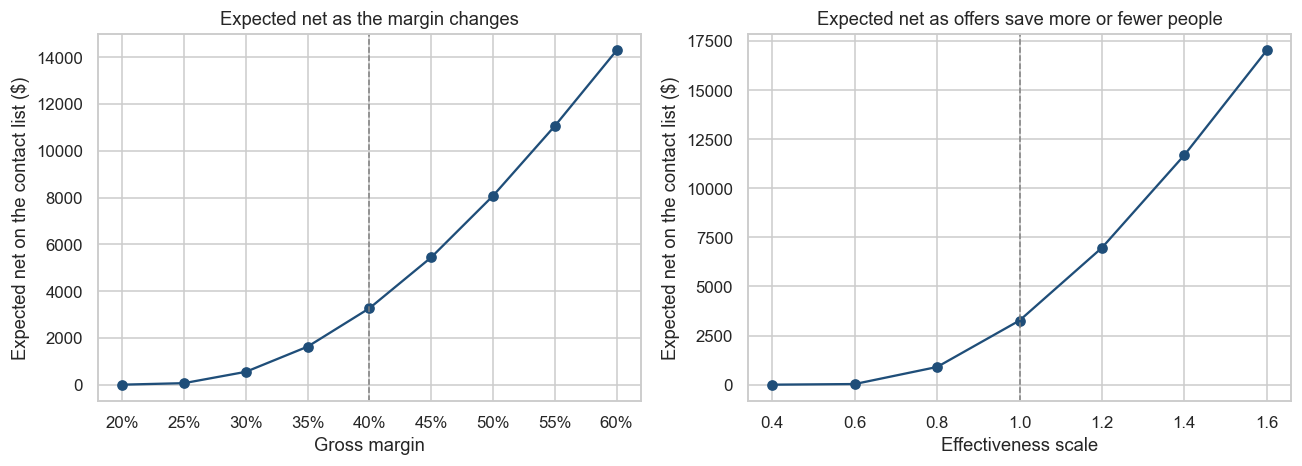

Customers worth contacting
By margin: 20% → 0, 25% → 61, 30% → 206, 35% → 405, 40% → 565, 45% → 732, 50% → 880, 55% → 985, 60% → 1069
By effectiveness scale: 0.4x → 0, 0.6x → 31, 0.8x → 294, 1.0x → 565, 1.2x → 823, 1.4x → 1007, 1.6x → 1142


In [24]:

margin_grid = np.round(np.arange(0.20, 0.61, 0.05), 2)
effectiveness_grid = np.round(np.arange(0.4, 1.61, 0.2), 2)
margin_net = []
margin_n = []
for margin in margin_grid:
    nets, _ = price_book(ranked, margin, 1.0, 1.0)
    margin_n.append(int((nets > 0).sum()))
    margin_net.append(float(nets[nets > 0].sum()) if np.any(nets > 0) else 0.0)
effect_net = []
effect_n = []
for scale in effectiveness_grid:
    nets, _ = price_book(ranked, MARGIN, scale, 1.0)
    effect_n.append(int((nets > 0).sum()))
    effect_net.append(float(nets[nets > 0].sum()) if np.any(nets > 0) else 0.0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].plot(margin_grid, margin_net, marker="o", color="#1f4e79")
axes[0].axvline(MARGIN, color="gray", linestyle="--", linewidth=1)
axes[0].set_title("Expected net as the margin changes")
axes[0].set_xlabel("Gross margin")
axes[0].set_ylabel("Expected net on the contact list ($)")
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].plot(effectiveness_grid, effect_net, marker="o", color="#1f4e79")
axes[1].axvline(1.0, color="gray", linestyle="--", linewidth=1)
axes[1].set_title("Expected net as offers save more or fewer people")
axes[1].set_xlabel("Effectiveness scale")
axes[1].set_ylabel("Expected net on the contact list ($)")
fig.tight_layout()
plt.show()

print("Customers worth contacting")
print("By margin:", ", ".join(f"{m:.0%} → {n}" for m, n in zip(margin_grid, margin_n)))
print("By effectiveness scale:", ", ".join(f"{s:.1f}x → {n}" for s, n in zip(effectiveness_grid, effect_n)))


## Split a pilot into an offer group and a holdout

The dollar totals move sharply when the save rate changes, and a weaker save rate shrinks the contact list. The next measurement is a small controlled pilot, not a larger model.

Take the 80 current subscribers with the highest expected net under the base assumptions. Within each offer type, assign half to receive that offer and half to a holdout that is not contacted. The holdout is what makes the later retention comparison meaningful. The split uses a fixed random seed so the assignment stays the same if this cell is run again.


In [25]:
PILOT_SIZE = 80
pilot_pool = queue.nsmallest(PILOT_SIZE, "priority_rank").copy()
assigned = []
for offer_name, group in pilot_pool.groupby("recommended_offer", sort=False):
    shuffled = group.sample(frac=1, random_state=RANDOM_STATE)
    holdout_n = len(shuffled) // 2
    labels = np.array(["Holdout"] * holdout_n + ["Offer"] * (len(shuffled) - holdout_n))
    shuffled = shuffled.copy()
    shuffled["pilot_group"] = labels
    assigned.append(shuffled)
pilot = pd.concat(assigned, axis=0)
pilot["action"] = np.where(
    pilot["pilot_group"] == "Offer",
    "Make the recommended offer",
    "Do not contact",
)
pilot["arm_order"] = pilot["pilot_group"].map({"Offer": 0, "Holdout": 1})
pilot = pilot.sort_values(["arm_order", "priority_rank"])

for column in [
    "contact_date",
    "offer_accepted",
    "incentive_paid",
    "subscribed_on_day_30",
    "subscribed_on_day_90",
    "notes",
]:
    pilot[column] = ""

arm_summary = (
    pilot.groupby("pilot_group")
    .agg(
        customers=("customerID", "size"),
        mean_probability=("churn_probability", "mean"),
        mean_monthly_bill=("MonthlyCharges", "mean"),
        expected_net=("expected_net_value", "sum"),
    )
    .reindex(["Offer", "Holdout"])
)
print(f"Pilot customers: {len(pilot)}")
display(arm_summary.round(2))
display(
    pd.crosstab(pilot["recommended_offer"], pilot["pilot_group"]).reindex(columns=["Offer", "Holdout"])
)


Pilot customers: 80


,customers,mean_probability,mean_monthly_bill,expected_net
pilot_group,,,,
Offer,41,0.67,95.22,535.62
Holdout,39,0.67,95.98,520.32


pilot_group,Offer,Holdout
recommended_offer,,
Annual contract save,10,10
Early-life credit,16,15
Tech support bundle,15,14


## Save the pilot sheet and the readout rule

`pilot_sheet.csv` is the working file for the calls. Fill `contact_date`, `offer_accepted`, `incentive_paid`, and the two subscription fields as the 90 days pass. Leave the holdout rows untouched.

The bar for expanding the program is set before any calls are made. It uses the planned contact cost and incentive on the offer arm, and each customer's own bill. After day 90, expand past this pilot only if the offer group's retention exceeds the holdout by at least that many percentage points.


In [26]:
offer_arm = pilot.loc[pilot["pilot_group"] == "Offer"].copy()
planned_cost = float(offer_arm["expected_offer_cost"].sum())
value_if_retained = float((offer_arm["MonthlyCharges"] * HORIZON_MONTHS * MARGIN).sum())
break_even_customers = planned_cost / (value_if_retained / len(offer_arm))
break_even_lift = break_even_customers / len(offer_arm)

pilot_cols = [
    "pilot_group",
    "action",
    "priority_rank",
    "customerID",
    "churn_probability",
    "recommended_offer",
    "incentive_face_value",
    "expected_net_value",
    "expected_offer_cost",
    "MonthlyCharges",
    "tenure",
    "Contract",
    "InternetService",
    "PaymentMethod",
    "top_risk_drivers",
    "contact_date",
    "offer_accepted",
    "incentive_paid",
    "subscribed_on_day_30",
    "subscribed_on_day_90",
    "notes",
]
pilot_path = "pilot_sheet.csv"
pilot[pilot_cols].to_csv(pilot_path, index=False)

preview = [
    "pilot_group",
    "action",
    "priority_rank",
    "customerID",
    "churn_probability",
    "recommended_offer",
    "expected_net_value",
]
print("First rows of the offer arm")
display(pilot.loc[pilot["pilot_group"] == "Offer", preview].head(10).round(3))

readout = f"""
### Pilot readout

- Offer arm: **{len(offer_arm)}** customers. Holdout: **{(pilot["pilot_group"] == "Holdout").sum()}** customers.
- Planned cost of contacting the offer arm and paying the expected incentives: **${planned_cost:,.0f}**.
- If one extra offer-arm customer is still subscribed after 90 days, the retained margin over six months averages **${value_if_retained / len(offer_arm):,.0f}**.
- Break-even: the offer arm needs about **{break_even_customers:.1f}** extra retained customers, which is **{break_even_lift:.1%}** higher 90-day retention than the holdout.
- File: `{pilot_path}`.
"""
display(Markdown(readout))
print(f"Wrote {len(pilot)} rows to {pilot_path}")


First rows of the offer arm


,pilot_group,action,priority_rank,customerID,churn_probability,recommended_offer,expected_net_value
1719,Offer,Make the recommended offer,2,2081-VEYEH,0.652,Early-life credit,18.22
2238,Offer,Make the recommended offer,3,1393-IMKZG,0.719,Early-life credit,17.36
2387,Offer,Make the recommended offer,5,6734-GMPVK,0.652,Early-life credit,17.19
2519,Offer,Make the recommended offer,9,4927-WWOOZ,0.735,Early-life credit,16.31
5307,Offer,Make the recommended offer,10,1941-HOSAM,0.744,Early-life credit,16.25
6567,Offer,Make the recommended offer,15,6215-NQCPY,0.703,Annual contract save,15.57
4701,Offer,Make the recommended offer,16,5956-YHHRX,0.680,Tech support bundle,15.57
4618,Offer,Make the recommended offer,18,6350-XFYGW,0.685,Early-life credit,14.97
5019,Offer,Make the recommended offer,19,3320-VEOYC,0.703,Annual contract save,14.58
3418,Offer,Make the recommended offer,21,4176-FXYBO,0.625,Tech support bundle,14.39



### Pilot readout

- Offer arm: **41** customers. Holdout: **39** customers.
- Planned cost of contacting the offer arm and paying the expected incentives: **$993**.
- If one extra offer-arm customer is still subscribed after 90 days, the retained margin over six months averages **$229**.
- Break-even: the offer arm needs about **4.3** extra retained customers, which is **10.6%** higher 90-day retention than the holdout.
- File: `pilot_sheet.csv`.


Wrote 80 rows to pilot_sheet.csv
